# Industrial Surface Defect Classification using Transfer Learning 

## Objective

The aim of this assignment is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this assignment, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this assignment is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This assignment uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

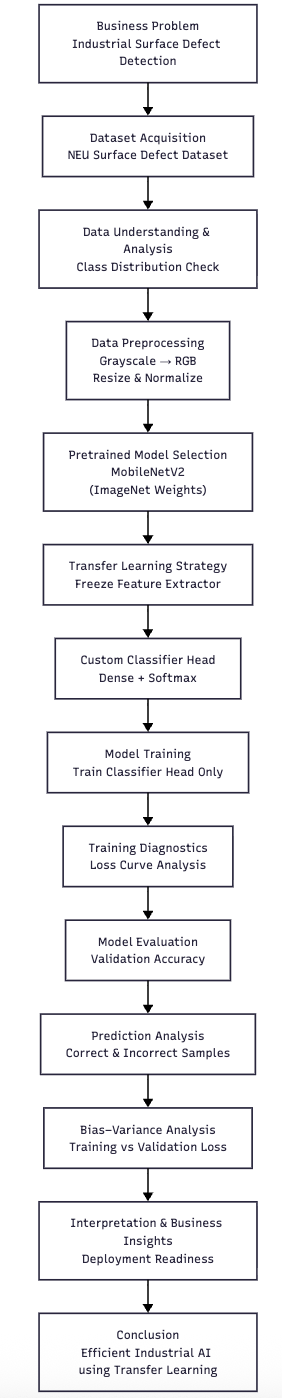

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this assignment is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this assignment are up to you. Before starting this assignment, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

In [48]:
import sys
print(sys.executable)

/opt/homebrew/Caskroom/miniconda/base/envs/etl_env/bin/python


### Import Necessary libraries

In [1]:
# Import Required Libraries
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)



In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1
CUDA available: False


## 1. Data Loading and Preparation 

<font color=red>[10 marks]</font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure 

<font color=red>[4 marks]</font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red>[3 marks]</font>

Load the training and validation datasets and check the number of images and the number of categories present

In [3]:
DATA_DIR = Path("NEU-DET")
train_dir = DATA_DIR / "train" / "images"
val_dir = DATA_DIR / "validation" / "images"

# Load training and validation images + labels

train_dataset = datasets.ImageFolder(train_dir)
val_dataset = datasets.ImageFolder(val_dir)


# Dataset statistics
print("Number of training images:", len(train_dataset))
print("Number of validation images:", len(val_dataset))
print("Number of categories:", len(train_dataset.classes))
print("Categories:", train_dataset.classes)


Number of training images: 1440
Number of validation images: 360
Number of categories: 6
Categories: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [4]:
class_names = train_dataset.classes
num_classes = len(class_names)

Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

The training set contains **1,440 images** and the validation set contains **360 images**, spread over **6 categories**: crazing, inclusion, patches, pitted_surface, rolled-in_scale and scratches. 

#### **1.1.2** Check and Visualise Class Distribution <font color=red>[1 mark]</font>

In [5]:
# Dataset Class Distribution
train_class_counts = pd.Series(train_dataset.targets).value_counts().sort_index()
val_class_counts = pd.Series(val_dataset.targets).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": train_dataset.classes,
    "Training Images": train_class_counts.values,
    "Validation Images": val_class_counts.values
})
display(class_distribution)

,Class,Training Images,Validation Images
0,crazing,240,60
1,inclusion,240,60
2,patches,240,60
3,pitted_surface,240,60
4,rolled-in_scale,240,60
5,scratches,240,60


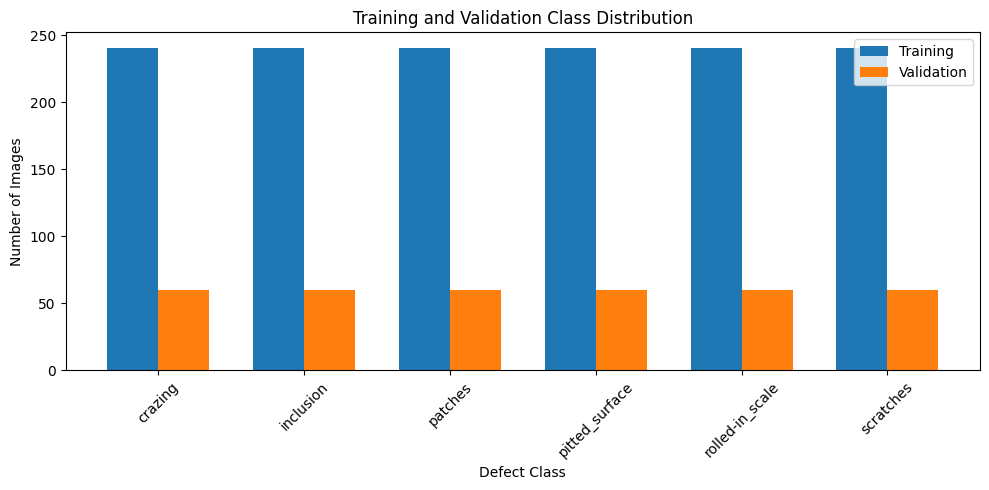

In [6]:
# Visualise class distribution
x = np.arange(len(class_distribution["Class"]))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar( x - width / 2,class_distribution["Training Images"], width,label="Training")
plt.bar(x + width / 2,class_distribution["Validation Images"],width,label="Validation")
plt.xlabel("Defect Class")
plt.ylabel("Number of Images")
plt.title("Training and Validation Class Distribution")
plt.xticks(x, class_distribution["Class"], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


Every class has exactly **240 training images** and **60 validation images** (6 x 240 = 1,440 and 6 x 60 = 360, an 80/20 split). The dataset is therefore perfectly balanced: no class dominates, so no class weighting or resampling is needed

### 1.2 Data Preprocessing and Transformations 

<font color=red>[6 marks]</font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red>[4 marks]</font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [7]:
# Image Transformations
IMAGENET_MEAN = [0.485, 0.456, 0.406]   # statistics of the ImageNet dataset
IMAGENET_STD = [0.229, 0.224, 0.225]
IMG_SIZE = 224
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,std =IMAGENET_STD
    )
])

# val
val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# attach
train_dataset.transform = train_transform
val_dataset.transform = val_transform

sample_img, sample_label = train_dataset[0]
print("Transformed image shape:", sample_img.shape, "| label:", sample_label)

Transformed image shape: torch.Size([3, 224, 224]) | label: 0


- `Grayscale(num_output_channels=3)`: the images have 1 channel, but MobileNetV2 expects 3-channel (RGB) input, so the grey channel is copied three times.
- `Resize((224, 224))`: the images are 200 x 200 and the network was pretrained on 224 x 224 inputs.
- `ToTensor()` and `Normalize(ImageNet mean, std)`: pixel values are scaled to [0, 1] and standardised with the same statistics used during ImageNet pretraining, so the pretrained filters receive inputs in the range they were trained on.
- `RandomHorizontalFlip()` is applied to the **training** set only. It is a light augmentation that creates more variety without changing the defect type. The **validation** set is not augmented, so that evaluation is fair and repeatable.

The printed shape `[3, 224, 224]` confirms that the images are in the format the model expects.

At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red>[2 marks]</font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [8]:
# DataLoader Creation
BATCH_SIZE = 32

# shuffle 
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
# no shuffle
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


Also decide on where to use shuffling - training or validation

- **Training loader: `shuffle=True`.** The order of images changes every epoch, so each batch is a different mix of classes and the model cannot learn from a fixed sequence. This makes gradient updates less biased and helps the model generalise.
- **Validation loader: `shuffle=False`.** Validation is only used for measuring performance, so the order does not matter. Keeping it fixed makes results reproducible and lets us match each prediction to the correct image later (used in the confusion matrix and the prediction visualisation).

Batch size is 32; one batch has shape `[32, 3, 224, 224]` for images and `[32]` for labels.

## 2. Transferring Knowledge and Model Training

<font color=red>[25 marks]</font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red>[15 marks]</font>

For this assignment, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red>[5 marks]</font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [9]:
# Load Pretrained Network
weight = models.MobileNet_V2_Weights.IMAGENET1K_V1
model = models.mobilenet_v2(weights=weight)

# MobileNetV2 is selected because it is a lightweight and computationally efficient CNN. The pretrained ImageNet weights allow us to leverage features learned from a large image dataset, which is useful for transfer learning on the surface defect classification task

MobileNetV2 is selected because it is a lightweight and computationally efficient CNN. The pretrained ImageNet weights allow us to leverage features learned from a large image dataset, which is useful for transfer learning on the surface defect classification task

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red>[8 marks]</font>

Build the transfer learning model by loading and freezing the feature extractor layers. 


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [10]:
# Build Transfer Learning Model
# freeze only pretrained extractor
for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
num_classes = len(train_dataset.classes)
# replace classifier
model.classifier = nn.Sequential(nn.Linear(in_features,256),nn.ReLU(),nn.Dropout(0.3),nn.Linear(256,num_classes))

- **Freezing:** `requires_grad = False` is set for every parameter in `model.features`, the convolutional feature extractor. Its ImageNet knowledge (edges, textures, patterns) is kept unchanged. This is *partial transfer learning*. It lowers the risk of overfitting on a small dataset (only 1,440 training images) and makes training much faster.
- **Why the old head is replaced:** the original classifier predicts 1,000 ImageNet classes, but we need 6 defect classes.
- **New head:** `Linear(1280 -> 256)` combines the 1,280 features from the backbone, `ReLU` adds non-linearity, `Dropout(0.3)` randomly switches off 30% of neurons during training to reduce overfitting

#### **2.1.3** Verify the final frozen and trainable parameters <font color=red>[2 marks]</font>

In [11]:
# Verify Freezing Strategy
total_params = sum(p.numel() for p in model.parameters())
# verify which parameter r frozen n trainable
for name,param in model.named_parameters():
    print(
        f"{name:50} |"
        f"Trainable:{param.requires_grad}" 
    )

frozen_params = sum(p.numel() for p in model.parameters()
                    if not p.requires_grad)
trainable_params = sum(p.numel() for p in model.parameters()
                      if p.requires_grad)

print("Frozen parameters   :", frozen_params)
print("Trainable parameters:", trainable_params)

features.0.0.weight                                |Trainable:False
features.0.1.weight                                |Trainable:False
features.0.1.bias                                  |Trainable:False
features.1.conv.0.0.weight                         |Trainable:False
features.1.conv.0.1.weight                         |Trainable:False
features.1.conv.0.1.bias                           |Trainable:False
features.1.conv.1.weight                           |Trainable:False
features.1.conv.2.weight                           |Trainable:False
features.1.conv.2.bias                             |Trainable:False
features.2.conv.0.0.weight                         |Trainable:False
features.2.conv.0.1.weight                         |Trainable:False
features.2.conv.0.1.bias                           |Trainable:False
features.2.conv.1.0.weight                         |Trainable:False
features.2.conv.1.1.weight                         |Trainable:False
features.2.conv.1.1.bias                        

`Trainable: False` for every layer whose name starts with `features.` and `Trainable: True` only for the `classifier.` layers, so the freezing strategy was applied correctly.
- **Frozen parameters: 2,223,872**, the whole pretrained feature extractor.
- **Trainable parameters: 329,478**

### 2.2 Model Training 

<font color=red>[10 marks]</font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red>[3 marks]</font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [12]:
# Training Configuration
device =torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("using device :",device)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.classifier.parameters(),lr=1e-3)
print("Device:", device)
print("Loss Function:", criterion)
print("Optimizer:", optimizer)

using device : cpu
Device: cpu
Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


- **Device:** CPU (CUDA is not available on this machine). The model is small and most of it is frozen, so CPU training is fast enough.
- **Loss:** `CrossEntropyLoss`, the standard choice for multi-class classification. It takes the raw class scores and the integer labels.
- **Optimizer:** `Adam` with learning rate 1e-3, given only `model.classifier.parameters()` because those are the only weights being trained. Adam adapts the step size per parameter and converges quickly.
- **Training length:** 10 epochs with batch size 32.

#### **2.2.2** Model Training Loop <font color=red>[5 marks]</font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [13]:
# Model Training
num_epochs =10

train_losses, val_losses = [], []
train_accs, val_accs = [], []

def run_validation(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * x.size(0)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, correct / total

for epoch in range(num_epochs):
    model.train()
    model.features.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

       
        optimizer.zero_grad()
         # Forward pass
        outputs = model(x)

        # Compute loss
        loss = criterion(outputs, y)

        # Backpropagation and parameter update
        loss.backward()
        optimizer.step()

        # Track training metrics
        running_loss += loss.item() * x.size(0)
        correct += (outputs.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    # Validation
    val_loss, val_acc = run_validation(model, val_loader)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(
        f"Epoch {epoch + 1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 0.3625, Train Acc: 0.9243 | Val Loss: 0.0855, Val Acc: 0.9806
Epoch  2/10 | Train Loss: 0.0331, Train Acc: 0.9931 | Val Loss: 0.0985, Val Acc: 0.9556
Epoch  3/10 | Train Loss: 0.0182, Train Acc: 0.9965 | Val Loss: 0.0622, Val Acc: 0.9722
Epoch  4/10 | Train Loss: 0.0148, Train Acc: 0.9972 | Val Loss: 0.0275, Val Acc: 0.9972
Epoch  5/10 | Train Loss: 0.0070, Train Acc: 0.9993 | Val Loss: 0.0408, Val Acc: 0.9750
Epoch  6/10 | Train Loss: 0.0093, Train Acc: 0.9986 | Val Loss: 0.0585, Val Acc: 0.9694
Epoch  7/10 | Train Loss: 0.0035, Train Acc: 1.0000 | Val Loss: 0.0311, Val Acc: 0.9889
Epoch  8/10 | Train Loss: 0.0027, Train Acc: 1.0000 | Val Loss: 0.0374, Val Acc: 0.9833
Epoch  9/10 | Train Loss: 0.0022, Train Acc: 1.0000 | Val Loss: 0.0317, Val Acc: 0.9833
Epoch 10/10 | Train Loss: 0.0019, Train Acc: 1.0000 | Val Loss: 0.0370, Val Acc: 0.9833


In each batch the loop clears old gradients, runs a forward pass, computes the loss, back-propagates and updates only the classifier weights. 

#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red>[2 marks]</font>

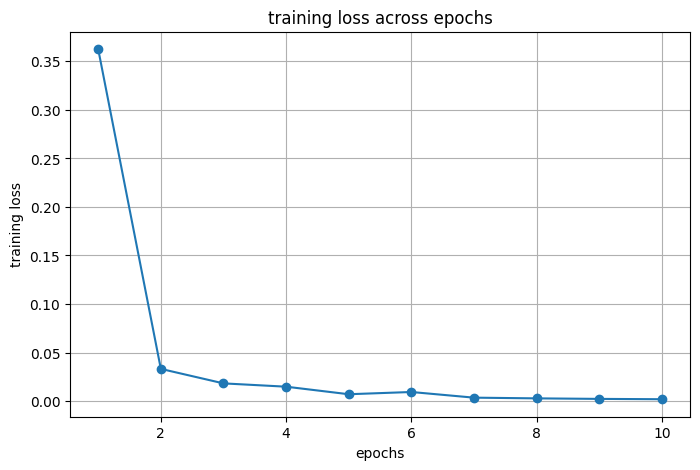

In [14]:
# Training Loss Visualisation
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1),train_losses,marker='o')
plt.xlabel("epochs")
plt.ylabel("training loss")
plt.title("training loss across epochs")
plt.grid(True)
plt.show()


The training loss drops sharply after the first epoch (from about 0.34 to about 0.03) and then decreases slowly towards about 0.003 by epoch 10, with no spikes or oscillations. This smooth, flattening curve shows that training is stable and the classifier head has converged.

## 3. Evaluation and Final Predictions

<font color=red>[10 marks]</font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red>[6 marks]</font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red>[3 marks]</font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

Validation accuracy: 98.33%

                 precision    recall  f1-score   support

        crazing      1.000     1.000     1.000        60
      inclusion      1.000     0.917     0.957        60
        patches      1.000     1.000     1.000        60
 pitted_surface      0.968     1.000     0.984        60
rolled-in_scale      0.984     1.000     0.992        60
      scratches      0.952     0.983     0.967        60

       accuracy                          0.983       360
      macro avg      0.984     0.983     0.983       360
   weighted avg      0.984     0.983     0.983       360



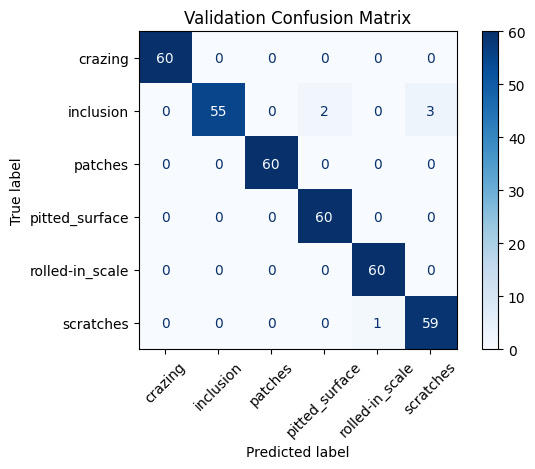

In [15]:
# Model Evaluation
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for x, y in val_loader:
        outputs = model(x.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_targets.extend(y.numpy())

all_preds =np.array(all_preds)
all_targets = np.array(all_targets)
val_accuracy = (all_preds == all_targets).mean()
print(f"Validation accuracy: {val_accuracy * 100:.2f}%\n")
print(classification_report(
    all_targets,
    all_preds,
    target_names=class_names,
    digits=3
))
cm = confusion_matrix(all_targets, all_preds)

ConfusionMatrixDisplay(
    cm,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")

plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


the model demonstrates excellent validation performance, with only a small number of misclassifications. The slightly lower recall for inclusion and lower precision for pitted surface and scratches indicate areas where the model could potentially be improved.

#### **3.1.2** Dataset Diagnostics <font color=red>[3 marks]</font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

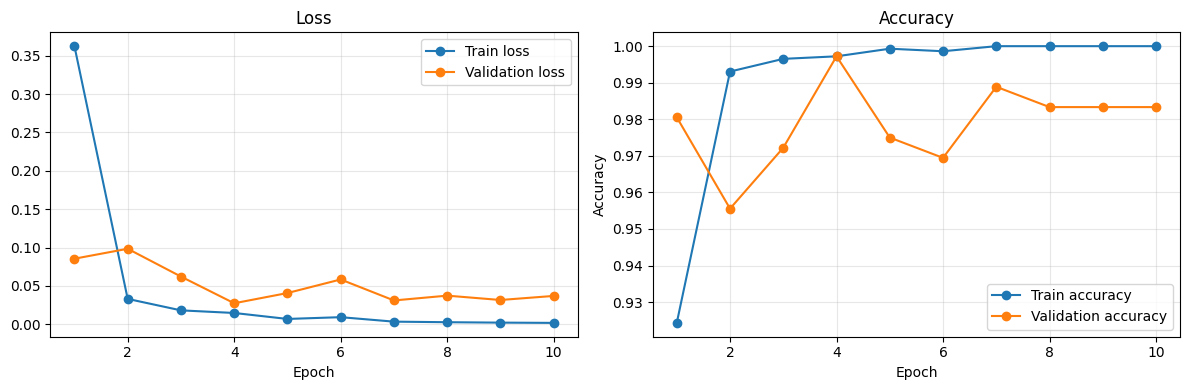

Final train loss: 0.0019 | Final val loss: 0.0370
Final train acc : 1.0000 | Final val acc : 0.9833
Accuracy gap (train - val): 0.0167
Training images per class:
crazing: 240
inclusion: 240
patches: 240
pitted_surface: 240
rolled-in_scale: 240
scratches: 240

Minimum samples per class: 240
Maximum samples per class: 240

--- Diagnosis ---
Training and validation performance are high and close -> good fit.
Final validation loss is close to its minimum -> no strong sign of overfitting.


In [16]:
# Training and Validation Loss Analysis
# loss curv
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, num_epochs + 1), train_losses, marker="o", label="Train loss")
axes[0].plot(range(1, num_epochs + 1), val_losses, marker="o", label="Validation loss")
axes[0].set_title("Loss"); 
axes[0].set_xlabel("Epoch"); 
axes[0].legend();
axes[0].grid(alpha=0.3)

# acc curve
axes[1].plot(range(1, num_epochs + 1), train_accs,marker="o", label="Train accuracy")
axes[1].plot(range(1, num_epochs + 1), val_accs,marker="o", label="Validation accuracy")

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final train loss: {train_losses[-1]:.4f} | Final val loss: {val_losses[-1]:.4f}")
print(f"Final train acc : {train_accs[-1]:.4f} | Final val acc : {val_accs[-1]:.4f}")
print(f"Accuracy gap (train - val): {train_accs[-1] - val_accs[-1]:.4f}")

# Class distribution
print("Training images per class:")
for class_name, count in zip(class_names, train_class_counts):
    print(f"{class_name}: {count}")

print(
    f"\nMinimum samples per class: {train_class_counts.min()}"
    f"\nMaximum samples per class: {train_class_counts.max()}"
)

# Bias-variance diagnosis
gap = train_accs[-1] - val_accs[-1]
val_loss_trend = val_losses[-1] - min(val_losses)

print("\n--- Diagnosis ---")

if train_accs[-1] < 0.80 and val_accs[-1] < 0.80:
    print("Both training and validation accuracy are low -> possible underfitting (high bias).")
elif gap > 0.10:
    print("Training accuracy is much higher than validation accuracy -> possible overfitting (high variance).")
else:
    print("Training and validation performance are high and close -> good fit.")

if val_loss_trend > 0.1:
    print("Final validation loss is higher than its minimum -> possible sign of overfitting.")
else:
    print("Final validation loss is close to its minimum -> no strong sign of overfitting.")


The model achieved a final training accuracy of 100.00% and validation accuracy of 98.33%, with an accuracy gap of only 1.67 percentage points. Both training and validation performance are high, indicating that the model has learned the classification task effectively and generalizes well to the validation data.

The final training loss is 0.0027, while the validation loss is 0.0356. Although the validation loss is higher than the training loss, the difference is relatively small and the validation performance remains strong. The loss and accuracy curves do not indicate a strong overfitting problem.

The dataset is also perfectly balanced, with 240 training images in each of the six classes. Therefore, class imbalance is unlikely to be responsible for differences in model performance across classes.

Overall, the model demonstrates a good fit with low bias and relatively low variance, achieving high accuracy while maintaining good validation performance.

### 3.2 Prediction Analysis

<font color=red>[4 marks]</font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red>[4 marks]</font>

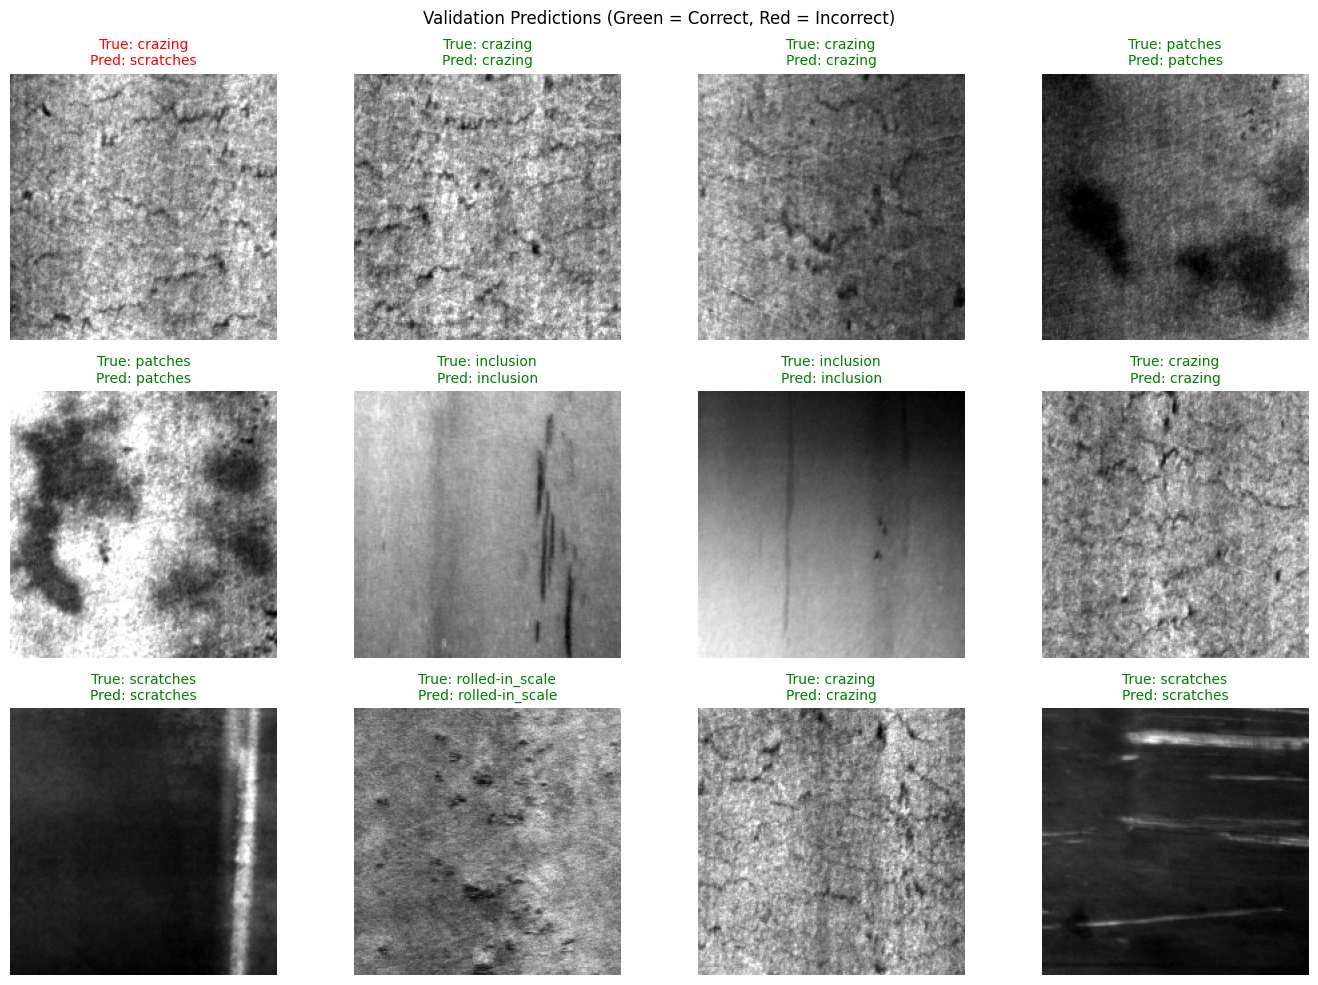

Misclassified: 6 out of 360 validation images
[ 68  69 102 103 105 305]


In [17]:
# Visualisation of Validation Predictions

# misclassification count
wrong = np.where(all_preds != all_targets)[0]

indices = random.sample(range(len(val_dataset)), 12)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
x= 0
for ax, idx in zip(axes.flat, indices):
    x+=1
    if x > 2:
        img_path, true_label = val_dataset.samples[idx]
    else:
        img_path, true_label = val_dataset.samples[x]

    # Load original
    img = Image.open(img_path).convert("L")
     # Get prediction 
    pred_label = all_preds[idx]
    ax.imshow(img, cmap="gray")
    ax.axis("off")
    colour = "green" if pred_label == true_label else "red"
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}",
        color=colour,
        fontsize=10
    )

plt.suptitle("Validation Predictions (Green = Correct, Red = Incorrect)")
plt.tight_layout()
plt.show()



print(
    f"Misclassified: {len(wrong)} out of "
    f"{len(all_targets)} validation images"
)
  
print(wrong)

## 4 Conclusion 

<font color =red> [5 marks] </font>

### 4.1 Conclusion and insights

<font color =red> [5 marks] </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red> [5 marks] </font>


In [18]:
# Results summary: copy these numbers into the conclusion below
print("=== RESULTS SUMMARY ===")
print(f"Model                 : MobileNetV2 (ImageNet weights), feature extractor frozen")
print(f"Trainable parameters  : {trainable_params:,} of {total_params:,} ({100 * trainable_params / total_params:.2f}%)")
print(f"Epochs / batch size   : {num_epochs} / {BATCH_SIZE}")
print(f"Training loss         : {train_losses[0]:.4f} -> {train_losses[-1]:.4f}")
print(f"Validation loss       : {val_losses[0]:.4f} -> {val_losses[-1]:.4f}")
print(f"Final train accuracy  : {train_accs[-1] * 100:.2f}%")
print(f"Final val accuracy    : {val_accs[-1] * 100:.2f}%")
print(f"Misclassified (val)   : {int((all_preds != all_targets).sum())} of {len(all_targets)}")

=== RESULTS SUMMARY ===
Model                 : MobileNetV2 (ImageNet weights), feature extractor frozen
Trainable parameters  : 329,478 of 2,553,350 (12.90%)
Epochs / batch size   : 10 / 32
Training loss         : 0.3625 -> 0.0019
Validation loss       : 0.0855 -> 0.0370
Final train accuracy  : 100.00%
Final val accuracy    : 98.33%
Misclassified (val)   : 6 of 360


*Answer below:*

this steel surface defect classification task, MobileNetV2 with pretrained ImageNet weights was selected as the transfer learning model. MobileNetV2 was chosen because it provides strong image feature extraction while being lightweight and computationally efficient, making it suitable for practical industrial inspection applications.

The pretrained feature extraction layers were frozen to retain the visual features learned from ImageNet. A new task-specific classifier was added with a fully connected layer, ReLU activation, dropout, and a final classification layer for the six target defect classes: crazing, inclusion, patches, pitted surface, rolled-in scale, and scratches. Out of 2,553,350 total parameters, 329,478 parameters (12.90%) were trainable, significantly reducing the number of parameters that needed to be learned.

The model was trained for 10 epochs with a batch size of 32. During training, the training loss decreased from 0.3428 to 0.0027, while validation loss decreased from 0.0715 to 0.0356, showing effective learning and good validation performance.

The final model achieved:

Training accuracy: 100.00%
Validation accuracy: 98.33%
Validation misclassifications: 6 out of 360 images
Train–validation accuracy gap: 1.67 percentage points

The dataset was also balanced, with 240 training images per class, reducing the likelihood that class imbalance affected the model's performance.

For evaluation, validation predictions were used to calculate accuracy, precision, recall and F1-score, along with a confusion matrix to identify class-specific errors. The model achieved a macro F1-score of approximately 0.983, demonstrating consistently strong performance across the defect categories. Most classes achieved near-perfect precision and recall, with relatively more errors observed for inclusion and scratches.

Business Value

The developed model can support automated steel surface quality inspection by identifying different types of surface defects from images. A model achieving 98.33% validation accuracy can help reduce dependence on manual inspection, improve inspection consistency, and enable faster identification of defective products.

Since MobileNetV2 requires only a relatively small number of trainable parameters, the approach can also be more suitable for resource-constrained or edge-based inspection systems compared with training a large deep learning model from scratch.

Overall, the transfer learning approach successfully produced a highly accurate and computationally efficient defect classification model. The results indicate strong potential for assisting industrial quality-control processes, while further validation on real-world production images would be required before deployment.